In [11]:
import sys
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v1 import Moire
import utils

#### Create Moiré system

In [12]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=7)

### Band structure

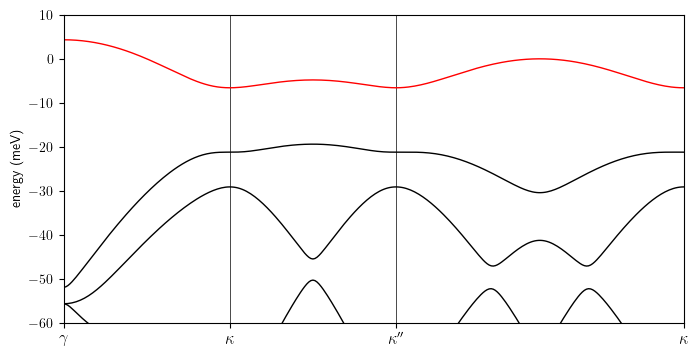

In [13]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)

fig, ax = plt.subplots(figsize=(8, 4))
sys.plot_bands(ax, bands, kdist, ticks, max_bands=4)
plt.ylim([-60, 10])
plt.savefig("plots/bands.pdf", dpi=300, bbox_inches='tight')

### Moiré potential

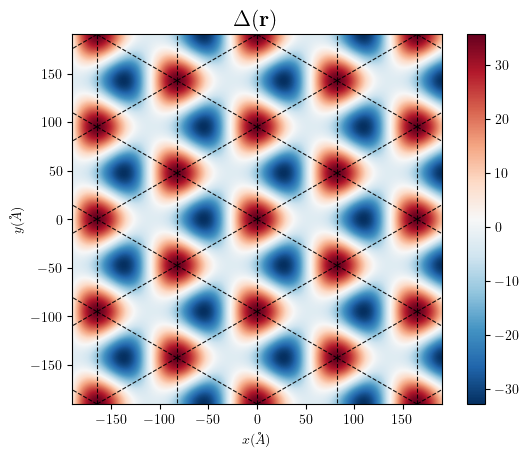

In [14]:
fig, ax = plt.subplots()
scale = 2.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=400)
fig.colorbar(im, ax=ax)
sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x (\AA)$')
ax.set_ylabel(r'$y (\AA)$')
ax.set_title(r'$\Delta(\mathbf{r})$', fontsize=16)
plt.savefig("plots/moire_potential.pdf", dpi=300, bbox_inches='tight')

### Wannier function

Text(0, 0.5, '$y$ (Å)')

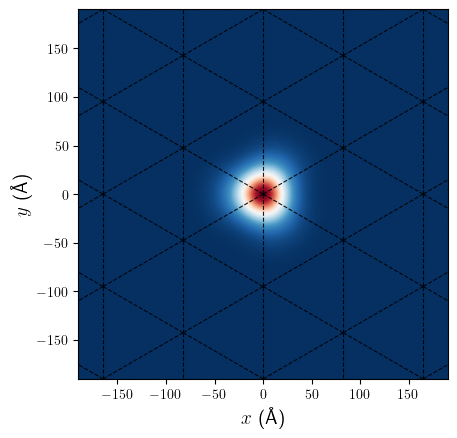

In [15]:
fig, ax = plt.subplots()
k_points = sys.mesh_k_unit_cell()
x = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
y = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
X, Y = np.meshgrid(x, y)
sys.plot_wannier_function(ax, X, Y, k_points)
sys.plot_triangular_lattice(ax, extent)

plt.xlabel(r'$x$ (Å)', fontsize=14)
plt.ylabel(r'$y$ (Å)', fontsize=14)

### Berry curvature

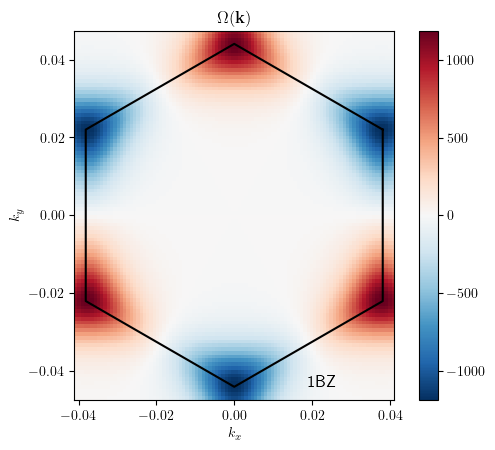

In [16]:
fig, ax = plt.subplots()
scale = 1.1
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_berry_curvature(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/berry.pdf", dpi=300, bbox_inches='tight')

### Quantum metric

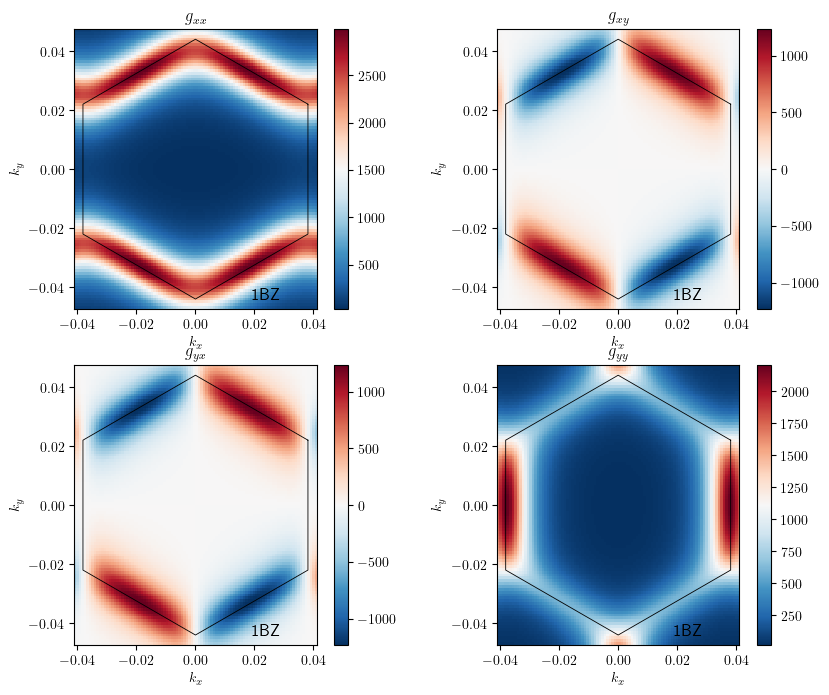

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
scale = 1.1
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/metric.pdf", dpi=300, bbox_inches='tight')

Text(611.395656730037, 0.5, '$k_y$')

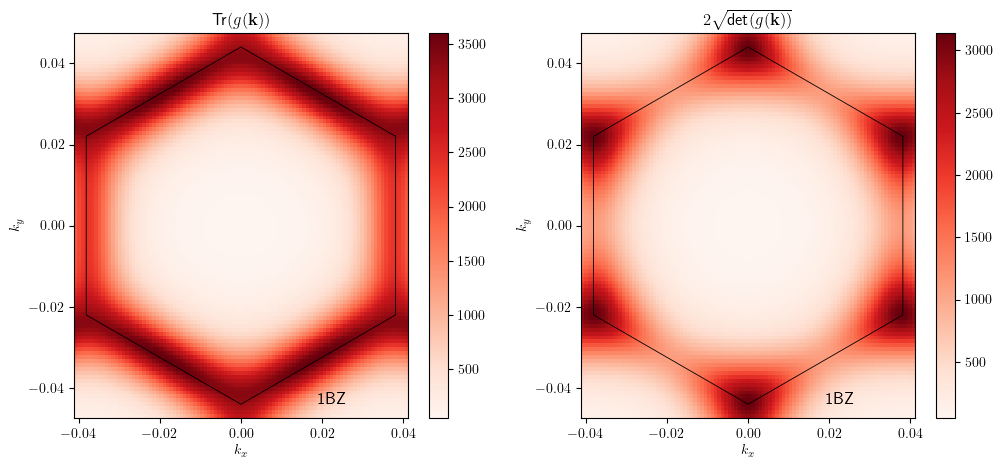

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
scale = 1.1
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric(ax, KX, KY)
plt.savefig("plots/trace.pdf", dpi=300, bbox_inches='tight')

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

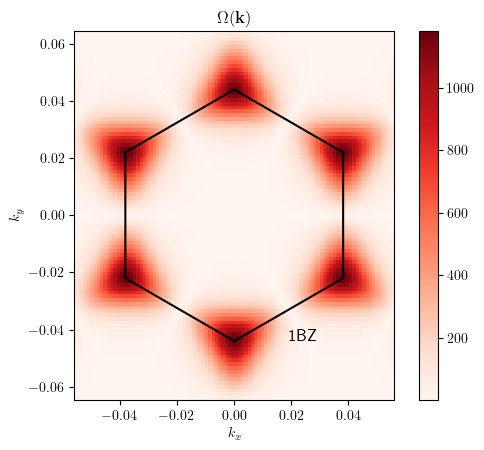

In [19]:
fig, ax = plt.subplots()
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_berry_curvature(ax, KX, KY, abs_val=True)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')